# ADP 모의고사 4회 - 복원 연습

출처: 모의고사 4.ipynb

**복원 연습 자료·예시 풀이이며 공식 정답이 아닙니다.** 원 데이터가 첨부되지 않아 동일 컬럼·분석 주제의 합성 연습 자료를 제공합니다. 수치 정답은 원 시험과 다릅니다.

동봉 data를 사용하며 원 질문·보완 조건·풀이를 분리합니다. 입력 파일은 UTF-8. 저장소 루트 또는 현재 회차 폴더에서 실행할 수 있습니다.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.svm import SVC
from IPython.display import display
# repository root 또는 회차 폴더에서 탐색; 경로를 하드코딩하지 않음.
ROOT=next(p for p in [Path.cwd()]+list(Path.cwd().parents) if (p/'기출문제/공통/reconstruction.py').exists())
sys.path.insert(0,str(ROOT));sys.path.insert(0,str(ROOT/'기출문제/공통'))
from reconstruction import *
from matplotlib import font_manager
font_path=ROOT/'기출문제/공통/NanumGothic-Regular.ttf'
font_manager.fontManager.addfont(str(font_path))
plt.rcParams['font.family']='NanumGothic';plt.rcParams['axes.unicode_minus']=False
HERE=ROOT/'기출문제'/'모의고사/4회';DATA=HERE/'data';OUT=HERE/'실행결과';OUT.mkdir(exist_ok=True)
def load(name):return pd.read_csv(DATA/name)
print('데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님')


데이터 종류: 합성 복원 연습 자료, 원 시험 데이터가 아님


## 1. 호주 날씨 분류

자료: weatherAUS.csv

원자료 미첨부. 합성 10,520행과 NA 10,010개 열을 만들어 절대 10,000 조건을 그대로 연습.

### 1-1

데이터의 요약값을 보고 NA값이 10,000개 이상인 열을 제외하고 남은 변수 중 NA값이 있는 행을 제거하시오. 
그리고 AUS 데이터의 Date 변수를 Date형으로 변환하고, 
전처리가 완료된 weatherAUS 데이터를 train(70%), test(30%) 데이터로 분할하시오.
(set.seed(6789)를 실행한 후 데이터를 분할하시오.)

**출처/보완:** 첨부 모의고사 4.ipynb markdown cell 2

**풀이 근거:** 고정 열명 삭제 대신 결측 개수 조건을 검사합니다. 날짜 변환을 확인하고 Python 시드 6789로 7:3 분할합니다.

In [2]:
weather=load('weatherAUS.csv');print(weather.describe(include='all'));missing=weather.isna().sum();dropped=missing[missing>=10000].index.tolist()
weather=weather.drop(columns=dropped).dropna().copy();weather['Date']=pd.to_datetime(weather.Date)
print('제외 열:',dropped,'남은 행:',len(weather))
train,test=train_test_split(np.arange(len(weather)),test_size=.3,random_state=6789,stratify=weather.RainTomorrow)
print(len(train),len(test))

              Date Location  ...    Cloud9am  RainTomorrow
count        10520    10520  ...  510.000000         10520
unique       10520        3  ...         NaN             2
top     1995-01-01        A  ...         NaN           Yes
freq             1     3558  ...         NaN          5633
mean           NaN      NaN  ...    4.393580           NaN
std            NaN      NaN  ...    2.652514           NaN
min            NaN      NaN  ...    0.010161           NaN
25%            NaN      NaN  ...    2.022702           NaN
50%            NaN      NaN  ...    4.328582           NaN
75%            NaN      NaN  ...    6.770503           NaN
max            NaN      NaN  ...    8.966937           NaN

[11 rows x 6 columns]
제외 열: ['Cloud9am'] 남은 행: 10520
7364 3156


### 1-2

train 데이터로 종속변수인 RainTomorrow(다음날의 강수 여부)를 예측하는 분류모델을 
3개 이상 생성하고 test 데이터에 대한 예측값을 csv파일로 각각 제출하시오.

**출처/보완:** 첨부 모의고사 4.ipynb markdown cell 17

**풀이 근거:** 세 모델에서 같은 holdout을 사용해 예측 CSV를 각각 출력합니다. 다음날 강수 운영에는 미래 시간 분할로 추가 검증해야 합니다.

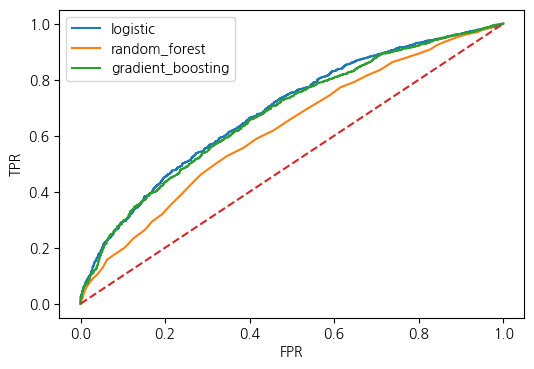

               model  accuracy  f1_weighted   ROC_AUC
0           logistic  0.633080     0.631101  0.686744
1      random_forest  0.583967     0.583705  0.621015
2  gradient_boosting  0.628961     0.627132  0.677582


In [3]:
weather_scores,weather_models,train,test=classify(weather,'RainTomorrow',[c for c in weather if c!='RainTomorrow'],OUT,seed=6789)

### 1-3(보충)

세 모델의 accuracy와 확률 기반 ROC-AUC를 비교하시오.

**출처/보완:** 모의고사 4 code cells 29~46

**풀이 근거:** 원본 질문 셀에는 없지만 첨부 code 29~46의 성과 분석을 보충문항으로 구분했습니다.

In [4]:
print(weather_scores);print('시간 순 운영에서는 랜덤분할 지표가 낙관적일 수 있습니다.')

               model  accuracy  f1_weighted   ROC_AUC
0           logistic  0.633080     0.631101  0.686744
1      random_forest  0.583967     0.583705  0.621015
2  gradient_boosting  0.628961     0.627132  0.677582
시간 순 운영에서는 랜덤분할 지표가 낙관적일 수 있습니다.


## 2. 자전거 마케팅 회귀

자료: bike_marketing.csv

marketing_total=세 채널 합계. 완전 공선성 때문에 4개 변수의 동시 투입 후보는 제외하고 식별 가능한 모델을 비교.

### 2-1

pop_density 변수를 factor형 변수로 변환하고, 
pop_density별 revenues의 평균 차이가 있는지 통계분석을 시행하여 결과를 해석하시오. 
만일 대립가설이 채택된다면 사후분석을 실시하고 결과를 해석하시오.

**출처/보완:** 첨부 모의고사 4.ipynb markdown cell 48

**풀이 근거:** H0: 인구밀집 범주별 평균 매출이 같습니다. p>=.05면 귀무가설을 기각하지 못합니다. 원문 “대립가설 기각” 표현을 바로잡습니다.

In [5]:
bike=load('bike_marketing.csv');bike['pop_density']=bike.pop_density.astype('category');anova(bike,'revenues','pop_density')

                      sum_sq     df        F    PR(>F)
C(pop_density)  3.002313e+04    2.0  0.55108  0.577359
Residual        4.603605e+06  169.0      NaN       NaN
유의하면 적어도 한 평균/효과가 다릅니다. 모든 쌍이 다르다는 뜻은 아닙니다.
등분산 Levene: LeveneResult(statistic=np.float64(0.10245579292560225), pvalue=np.float64(0.9026740722440879))
ANOVA 유의하지 않아 사후검정을 주 결론으로 수행하지 않습니다.
합성 자료의 예시 추론. 정규성·등분산·독립성 및 표본 설계를 실제 자료에서 재검증하세요.


### 2-2

google_adwords, facebook, twitter, marketing_total, employees가 
revenues에 영향을 미치는지 알아보는 회귀분석을 전진선택법을 사용하여 수행하고 결과를 해석하시오.

**출처/보완:** 첨부 모의고사 4.ipynb markdown cell 54

**풀이 근거:** 후보 추가로 AIC가 엄격하게 낮아질 때 전진합니다. 설계행렬 rank가 부족한 조합은 선택하지 않습니다.

In [6]:
bike_model=select_ols(bike,'revenues',['google_adwords','facebook','twitter','marketing_total','employees'],'forward')

선택 변수: ['google_adwords', 'employees', 'facebook']
   step                           features          AIC
0     1                     google_adwords  2157.874030
1     2           google_adwords,employees  1953.590440
2     3  google_adwords,employees,facebook  1908.456346
                            OLS Regression Results                            
Dep. Variable:               revenues   R-squared:                       0.863
Model:                            OLS   Adj. R-squared:                  0.861
Method:                 Least Squares   F-statistic:                     353.7
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           2.43e-72
Time:                        16:04:19   Log-Likelihood:                -950.23
No. Observations:                 172   AIC:                             1908.
Df Residuals:                     168   BIC:                             1921.
Df Model:                           3                                         
Covariance Typ

### 2-3

전진선택법을 사용해 변수를 선택한 후 새롭게 생성한 회귀모형에 대한 
잔차분석을 수행하고 결과를 해석하시오. 

**출처/보완:** 첨부 모의고사 4.ipynb markdown cell 58

**풀이 근거:** 정규성은 원 y가 아니라 잔차를 진단합니다. DW가 2에 가깝다는 사실만으로 관측 독립성을 입증하지 않습니다.

{'Shapiro_p': np.float64(0.6601921298427909), 'Breusch_Pagan_p': np.float64(0.8851551310809201), 'Durbin_Watson': np.float64(1.9460426637367119)}
p>=0.05는 귀무가설을 기각하지 못함입니다. 독립성은 관측 설계·시간 순서도 확인합니다.


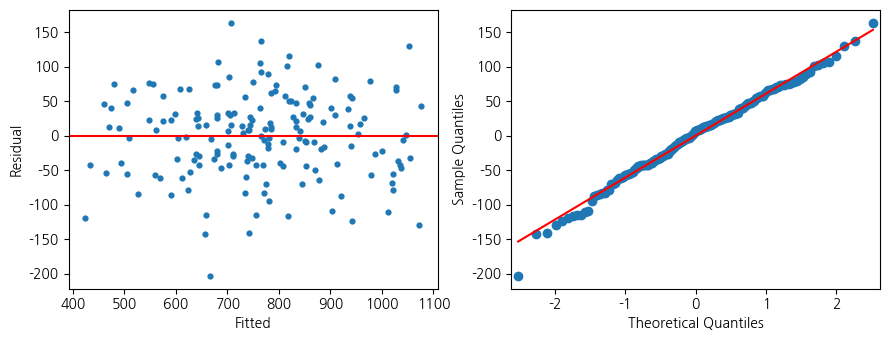

In [7]:
residual_diagnostics(bike_model)

## 3. 태교여행 텍스트

자료: instagram.csv + lexicon.csv



### 3-1

‘instagram_태교여행.txt’ 데이터를 읽어온 뒤 숫자, 특수 문자 등을 
제거하는 전처리 작업을 시행하시오.

**출처/보완:** 첨부 모의고사 4.ipynb markdown cell 79

**풀이 근거:** 텍스트 정제 뒤 원 문서와 대응을 유지합니다.

In [8]:
instagram=load('instagram.csv');lexicon=load('lexicon.csv');instagram['clean']=instagram.text.map(clean_text);print(instagram.head())

         date                            text                    clean
0  2026-01-15      호텔 맛 공구 영화 호텔 맛 즐겁다 123 !@      호텔 맛 공구 영화 호텔 맛 즐겁다
1  2026-01-16     호텔 행복 행복 맛 호텔 행복 즐겁다 123 !@     호텔 행복 행복 맛 호텔 행복 즐겁다
2  2026-01-17      배송 가족 여행 영화 호텔 맛 좋다 123 !@      배송 가족 여행 영화 호텔 맛 좋다
3  2026-01-18  영화 태교여행 여행 호텔 여행 가족 빠르다 123 !@  영화 태교여행 여행 호텔 여행 가족 빠르다
4  2026-01-19    학교 호텔 학교 학교 학교 행복 빠르다 123 !@    학교 호텔 학교 학교 학교 행복 빠르다


### 3-2

전처리된 데이터에서 “태교여행”이란 단어를 사전에 추가하고 명사를 추출해 
출현빈도 10위까지 막대그래프로 시각화하시오. 

**출처/보완:** 첨부 모의고사 4.ipynb markdown cell 89

**풀이 근거:** 태교여행은 합성 사전에 하나의 Noun 단위로 등록해 분리하지 않습니다. 실제 원문은 별도 형태소 사전 등록이 필요합니다.

   word  count
0    가족     41
1    여행     39
2    행복     38
3    공구     37
4    영화     36
5     맛     35
6  태교여행     34
7    학교     34
8    호텔     33
9    배송     33


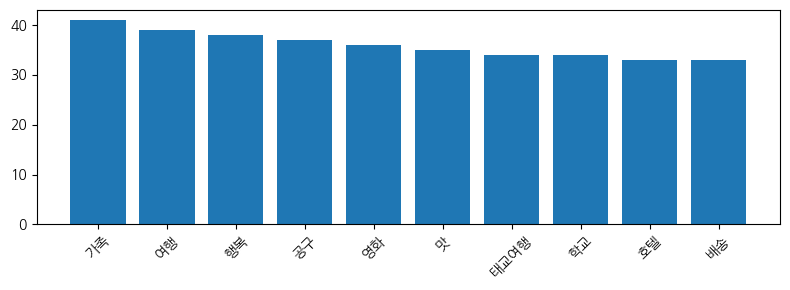

In [9]:
assert '태교여행' in lexicon.word.tolist();word_plot(lexical_pos(instagram.text,lexicon),10)